In [13]:
import os
import torch
from botorch import fit_gpytorch_mll
import botorch_tool
import copy
from botorch.sampling.normal import SobolQMCNormalSampler
from botorch.utils.transforms import unnormalize, normalize, standardize
import numpy as np
import pandas as pd
import json
from matplotlib import pyplot as plt
import pickle
from botorch.utils.transforms import standardize
from botorch.models.transforms.outcome import Standardize
from copy import copy

torch.set_default_dtype(torch.float64)

tkwargs = {
    "dtype": torch.double,
    "device": torch.device("cuda" if torch.cuda.is_available() else "cpu"),
}

BATCH_NUM = 10

In [14]:
exp_data_in = []
for BATCH_NUM_tmp in range(BATCH_NUM + 1):
    with open(f"./all_experiment_{BATCH_NUM_tmp}.json", "r") as f:
        exp_data_in.append(pd.DataFrame(json.load(f)))

exp_data_in = (
    pd.concat(exp_data_in)
    .sort_values(by=["substance1", "substance2", "volume1"])
    .reset_index(drop=True)
)

if not (exp_data_in.index.astype("int") == np.arange(len(exp_data_in))).all():
    raise ValueError("the index of the expeirments is not right")

# add noise from Pt experiments
exp_data_in["variance_S"] = exp_data_in["variance_S"] + 1.6
exp_data_in["variance_current"] = exp_data_in["variance_current"] + 198.53
exp_data_in

,substance1,substance2,substance3,substance4,substance5,volume1,volume2,volume3,volume4,volume5,voltage,mean_S,variance_S,mean_current,variance_current
0,Co,Al,Na3Cit,H3BO3,water,1.29,7.62,0.00,4.29,6.80,-1.50,12.908101,1.989316,88.513823,198.723137
1,Co,Al,Na3Cit,H3BO3,water,1.29,7.62,0.00,4.29,6.80,-0.20,13.551622,2.379844,120.299833,198.745309
2,Co,Al,Na3Cit,H3BO3,water,1.29,2.88,4.29,1.43,10.11,-2.70,11.095693,1.918337,43.513523,198.531849
3,Co,Al,Na3Cit,H3BO3,water,1.29,2.88,4.29,1.43,10.11,-1.63,11.984702,2.445643,66.204124,198.643052
4,Co,Al,Na3Cit,H3BO3,water,2.88,6.04,0.71,2.14,8.23,-2.52,13.573125,1.948430,98.077078,198.535109
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283,Ni,Cd,Na3Cit,H3BO3,water,7.62,1.29,0.00,0.71,10.38,-1.71,12.248693,2.551545,116.392154,198.611825
284,Ni,Cd,Na3Cit,H3BO3,water,7.79,2.71,0.79,3.78,4.94,-1.24,15.683106,2.422790,128.652859,199.566487
285,Ni,Cd,Na3Cit,H3BO3,water,7.79,2.71,0.79,3.78,4.94,-1.25,15.650465,2.943489,129.387298,198.720634
286,Ni,Cd,Na3Cit,H3BO3,water,7.90,1.09,0.00,4.58,6.43,-1.39,13.259777,1.679781,172.384641,199.249931


In [15]:
# get the unique conditions
unique_conditions = exp_data_in.iloc[:, 0:10].drop_duplicates()
exp_data = []
# for each unique condition, get the exp_result

for index in range(len(unique_conditions)):

    unique_condition = unique_conditions.iloc[index, 0:10]

    identical_index = (exp_data_in.iloc[:, 0:10] == unique_condition).all(axis=1)

    exp_results = exp_data_in.loc[identical_index]
    # if len(exp_results) != 2:
    #     continue
    display(exp_results)

    exp_temp = copy(unique_condition)

    exp_temp["mean_S"] = exp_results.mean_S.values.mean()
    exp_temp["variance_S"] = (
        exp_results.mean_S.values.var() + exp_results.variance_S.values.mean()
    )

    exp_temp["mean_current"] = exp_results.mean_current.values.mean()
    exp_temp["variance_current"] = (
        exp_results.mean_current.values.var()
        + exp_results.variance_current.values.mean()
    )

    exp_data.append(exp_temp)
exp_data = pd.DataFrame(exp_data)
display(exp_data)

,substance1,substance2,substance3,substance4,substance5,volume1,volume2,volume3,volume4,volume5,voltage,mean_S,variance_S,mean_current,variance_current
0,Co,Al,Na3Cit,H3BO3,water,1.29,7.62,0.0,4.29,6.8,-1.5,12.908101,1.989316,88.513823,198.723137
1,Co,Al,Na3Cit,H3BO3,water,1.29,7.62,0.0,4.29,6.8,-0.2,13.551622,2.379844,120.299833,198.745309


,substance1,substance2,substance3,substance4,substance5,volume1,volume2,volume3,volume4,volume5,voltage,mean_S,variance_S,mean_current,variance_current
2,Co,Al,Na3Cit,H3BO3,water,1.29,2.88,4.29,1.43,10.11,-2.70,11.095693,1.918337,43.513523,198.531849
3,Co,Al,Na3Cit,H3BO3,water,1.29,2.88,4.29,1.43,10.11,-1.63,11.984702,2.445643,66.204124,198.643052


,substance1,substance2,substance3,substance4,substance5,volume1,volume2,volume3,volume4,volume5,voltage,mean_S,variance_S,mean_current,variance_current
4,Co,Al,Na3Cit,H3BO3,water,2.88,6.04,0.71,2.14,8.23,-2.52,13.573125,1.948430,98.077078,198.535109
5,Co,Al,Na3Cit,H3BO3,water,2.88,6.04,0.71,2.14,8.23,-1.57,13.750742,1.957263,106.361603,198.564118


,substance1,substance2,substance3,substance4,substance5,volume1,volume2,volume3,volume4,volume5,voltage,mean_S,variance_S,mean_current,variance_current
6,Co,Al,Na3Cit,H3BO3,water,2.88,4.46,2.14,5.0,5.52,-1.37,11.943156,1.81635,100.570868,198.657071
7,Co,Al,Na3Cit,H3BO3,water,2.88,4.46,2.14,5.0,5.52,-1.49,13.009369,1.91368,98.920401,198.561806


,substance1,substance2,substance3,substance4,substance5,volume1,volume2,volume3,volume4,volume5,voltage,mean_S,variance_S,mean_current,variance_current
8,Co,Al,Na3Cit,H3BO3,water,2.88,1.29,5.0,0.0,10.83,-2.26,11.180192,2.141719,60.056227,198.567884
9,Co,Al,Na3Cit,H3BO3,water,2.88,1.29,5.0,0.0,10.83,-1.62,10.803707,3.370932,66.370033,198.543856


,substance1,substance2,substance3,substance4,substance5,volume1,volume2,volume3,volume4,volume5,voltage,mean_S,variance_S,mean_current,variance_current
10,Co,Al,Na3Cit,H3BO3,water,4.46,2.88,3.57,0.71,8.38,-2.92,11.552744,1.888408,114.028381,198.698410
11,Co,Al,Na3Cit,H3BO3,water,4.46,2.88,3.57,0.71,8.38,-3.19,11.519562,2.045078,132.090317,198.609339


... (118 outputs left out)

,substance1,substance2,substance3,substance4,substance5,volume1,volume2,volume3,volume4,volume5,voltage,mean_S,variance_S,mean_current,variance_current
282,Ni,Cd,Na3Cit,H3BO3,water,7.62,1.29,0.0,0.71,10.38,-1.69,12.121605,2.722044,124.933723,199.524656
283,Ni,Cd,Na3Cit,H3BO3,water,7.62,1.29,0.0,0.71,10.38,-1.71,12.248693,2.551545,116.392154,198.611825


,substance1,substance2,substance3,substance4,substance5,volume1,volume2,volume3,volume4,volume5,voltage,mean_S,variance_S,mean_current,variance_current
284,Ni,Cd,Na3Cit,H3BO3,water,7.79,2.71,0.79,3.78,4.94,-1.24,15.683106,2.422790,128.652859,199.566487
285,Ni,Cd,Na3Cit,H3BO3,water,7.79,2.71,0.79,3.78,4.94,-1.25,15.650465,2.943489,129.387298,198.720634


,substance1,substance2,substance3,substance4,substance5,volume1,volume2,volume3,volume4,volume5,voltage,mean_S,variance_S,mean_current,variance_current
286,Ni,Cd,Na3Cit,H3BO3,water,7.9,1.09,0.0,4.58,6.43,-1.39,13.259777,1.679781,172.384641,199.249931
287,Ni,Cd,Na3Cit,H3BO3,water,7.9,1.09,0.0,4.58,6.43,-3.11,13.486394,1.678600,166.469449,198.910152


,substance1,substance2,substance3,substance4,substance5,volume1,volume2,volume3,volume4,volume5,mean_S,variance_S,mean_current,variance_current
0,Co,Al,Na3Cit,H3BO3,water,1.29,7.62,0.00,4.29,6.80,13.229862,2.288110,104.406828,451.321831
2,Co,Al,Na3Cit,H3BO3,water,1.29,2.88,4.29,1.43,10.11,11.540197,2.379574,54.858823,327.303294
4,Co,Al,Na3Cit,H3BO3,water,2.88,6.04,0.71,2.14,8.23,13.661934,1.960734,102.219341,215.707949
6,Co,Al,Na3Cit,H3BO3,water,2.88,4.46,2.14,5.00,5.52,12.476262,2.149217,99.745634,199.290449
8,Co,Al,Na3Cit,H3BO3,water,2.88,1.29,5.00,0.00,10.83,10.991949,2.791761,63.213130,208.521908
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
278,Ni,Cd,Na3Cit,H3BO3,water,6.31,4.19,0.38,4.71,4.42,15.127512,2.016612,165.138481,199.663235
280,Ni,Cd,Na3Cit,H3BO3,water,6.44,4.06,0.00,3.25,6.25,15.930413,2.216798,141.836227,356.890607
282,Ni,Cd,Na3Cit,H3BO3,water,7.62,1.29,0.00,0.71,10.38,12.185149,2.640832,120.662938,217.307842
284,Ni,Cd,Na3Cit,H3BO3,water,7.79,2.71,0.79,3.78,4.94,15.666786,2.683406,129.020078,199.278411


In [25]:
metal_combo_original = np.concatenate(
    (
        exp_data["substance1"].values.reshape(-1, 1),
        exp_data["substance2"].values.reshape(-1, 1),
        exp_data["substance3"].values.reshape(-1, 1),
        exp_data["substance4"].values.reshape(-1, 1),
        exp_data["substance5"].values.reshape(-1, 1),
    ),
    axis=1,
).astype("str")
metal_combo = np.unique(metal_combo_original, axis=0)

In [26]:
metal_combo

array([['Co', 'Al', 'Na3Cit', 'H3BO3', 'water'],
       ['Co', 'Cd', 'Na3Cit', 'H3BO3', 'water'],
       ['Co', 'Mn', 'Na3Cit', 'H3BO3', 'water'],
       ['Cu', 'Cd', 'Na3Cit', 'H3BO3', 'water'],
       ['Cu', 'Mn', 'Na3Cit', 'H3BO3', 'water'],
       ['Cu', 'Y', 'Na3Cit', 'H3BO3', 'water'],
       ['Ni', 'Cd', 'Na3Cit', 'H3BO3', 'water']], dtype='<U6')

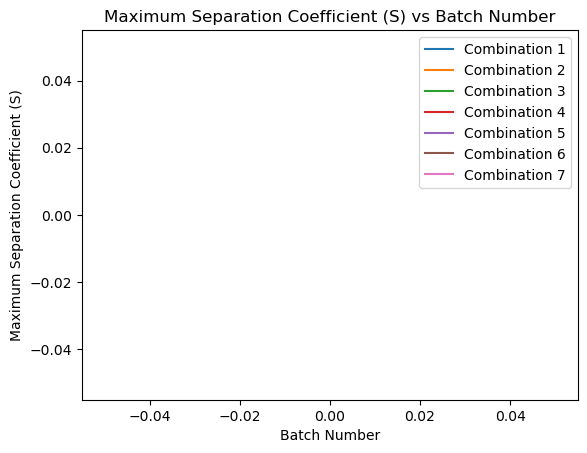

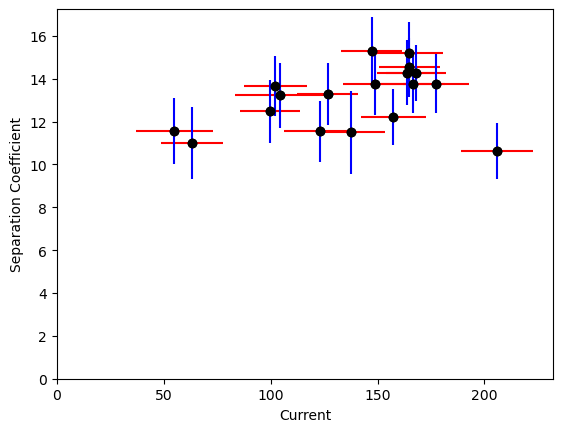

c:\Users\Admin\anaconda3\Lib\site-packages\botorch\models\utils\assorted.py:260: InputDataWarning: Data is not standardized (std = tensor([0.2029]), mean = tensor([0.0398])). Please consider scaling the input to zero mean and unit variance.
  check_standardization(Y=train_Y, raise_on_fail=raise_on_fail)


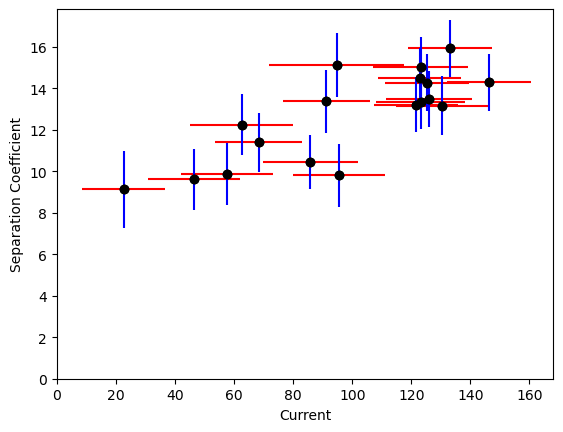

c:\Users\Admin\anaconda3\Lib\site-packages\botorch\models\utils\assorted.py:260: InputDataWarning: Data is not standardized (std = tensor([0.1635]), mean = tensor([-0.7884])). Please consider scaling the input to zero mean and unit variance.
  check_standardization(Y=train_Y, raise_on_fail=raise_on_fail)


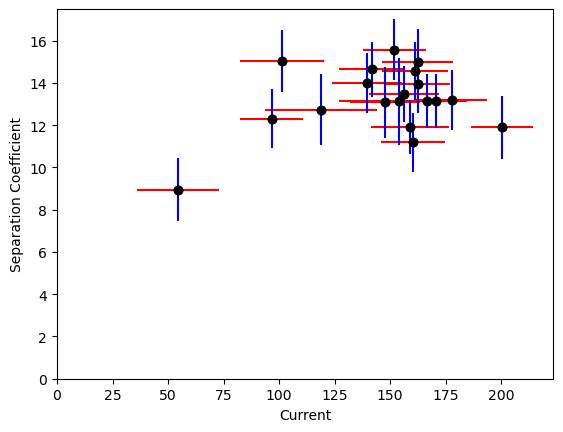

c:\Users\Admin\anaconda3\Lib\site-packages\botorch\models\utils\assorted.py:260: InputDataWarning: Data is not standardized (std = tensor([0.2321]), mean = tensor([-0.1470])). Please consider scaling the input to zero mean and unit variance.
  check_standardization(Y=train_Y, raise_on_fail=raise_on_fail)


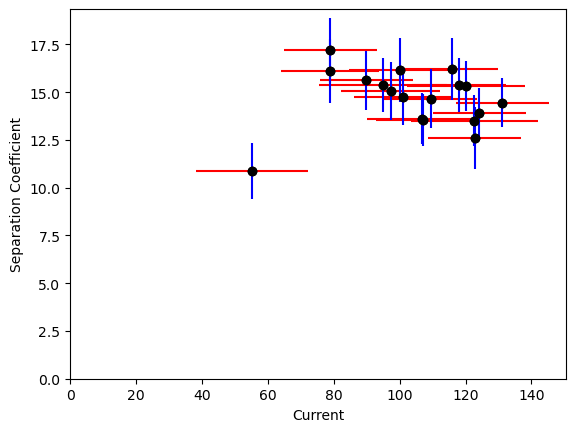

c:\Users\Admin\anaconda3\Lib\site-packages\botorch\models\utils\assorted.py:260: InputDataWarning: Data is not standardized (std = tensor([0.1851]), mean = tensor([-0.0383])). Please consider scaling the input to zero mean and unit variance.
  check_standardization(Y=train_Y, raise_on_fail=raise_on_fail)


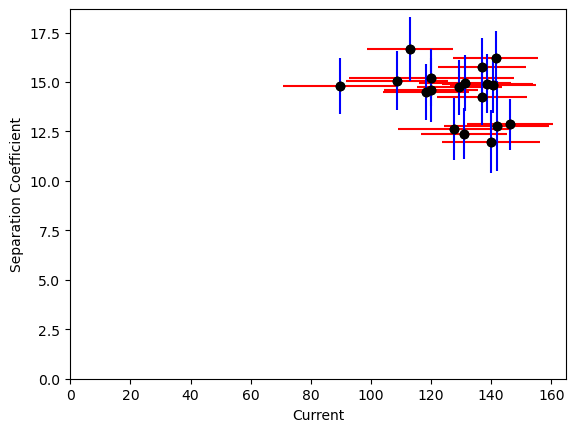

c:\Users\Admin\anaconda3\Lib\site-packages\botorch\models\utils\assorted.py:260: InputDataWarning: Data is not standardized (std = tensor([0.2478]), mean = tensor([0.2112])). Please consider scaling the input to zero mean and unit variance.
  check_standardization(Y=train_Y, raise_on_fail=raise_on_fail)


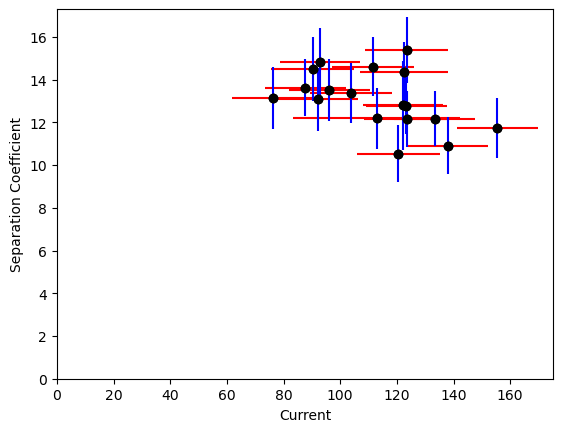

c:\Users\Admin\anaconda3\Lib\site-packages\botorch\models\utils\assorted.py:260: InputDataWarning: Data is not standardized (std = tensor([0.2192]), mean = tensor([0.1355])). Please consider scaling the input to zero mean and unit variance.
  check_standardization(Y=train_Y, raise_on_fail=raise_on_fail)


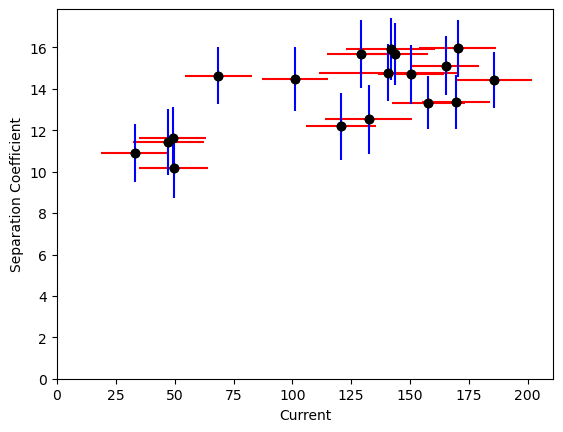

c:\Users\Admin\anaconda3\Lib\site-packages\botorch\models\utils\assorted.py:260: InputDataWarning: Data is not standardized (std = tensor([0.1564]), mean = tensor([-0.4716])). Please consider scaling the input to zero mean and unit variance.
  check_standardization(Y=train_Y, raise_on_fail=raise_on_fail)


In [5]:
from botorch.acquisition.monte_carlo import qNoisyExpectedImprovement

np.random.seed(42)
torch.manual_seed(42)

model_total = {}
y_train_total = []
x_train_total = []
failures = []


for i in range(7):
    # get the selected index
    selected_index = np.where(
        (metal_combo_original == metal_combo[i]).all(axis=1) == True
    )[0]

    plt.figure()
    plt.errorbar(
        exp_data.iloc[selected_index].mean_current,
        exp_data.iloc[selected_index].mean_S,
        color="black",
        xerr=np.sqrt(exp_data.iloc[selected_index].variance_current),
        fmt="o",
        ecolor="red",
        label="Variances",
    )

    plt.errorbar(
        exp_data.iloc[selected_index].mean_current,
        exp_data.iloc[selected_index].mean_S,
        color="black",
        yerr=np.sqrt(exp_data.iloc[selected_index].variance_S),
        fmt="o",
        ecolor="blue",
        label="Variances",
    )
    plt.ylim(0)
    plt.xlim(0)
    plt.xlabel("Current")
    plt.ylabel("Separation Coefficient")
    plt.show()
    plt.close()

    # read in the data
    x = []
    y_mean = []
    y_var = []

    # read in the data
    for j in selected_index:
        x.append(
            [
                (exp_data.iloc[j]["volume1"] - 0.5) / 9.5,
                (exp_data.iloc[j]["volume2"] - 0.5) / 9.5,
                (exp_data.iloc[j]["volume3"] / 5),
                (exp_data.iloc[j]["volume4"] / 5),
            ]
        )

        y_mean.append(exp_data.iloc[j]["mean_S"])
        y_var.append(exp_data.iloc[j]["variance_S"])

    # process the data input numpy array
    x = np.array(x).reshape(-1, 4)
    y_mean = np.array(y_mean).reshape(-1, 1)
    y_var = np.array(y_var).reshape(-1, 1)

    # if the data is not empty, perform machine learning
    if len(x) > 0:
        # initialize the machine learning models for
        train_x = torch.tensor(x).reshape(-1, 4)
        train_y = torch.tensor(np.concatenate([y_mean], axis=1))
        train_y_var = torch.tensor(np.concatenate([y_var], axis=1))

        # add the data to the whole data set
        y_train_total.append(train_y)
        x_train_total.append(train_x)
        # initialize the model
        mll, model = botorch_tool.tools.initialize_heter_noise_model(
            train_x=train_x, train_obj=train_y, train_obj_var=train_y_var
        )
        # fit the model
        try:
            fit_gpytorch_mll(mll)
        except:
            print(f"fitting noiseless model for combination {i}")
            failures.append(i)
            try:
                # initialize the noiseless model (not really noiseless, because the noise is estimated by the means)
                mll, model = botorch_tool.tools.initialize_noiseless_model(
                    train_x=train_x, train_obj=train_y
                )
                fit_gpytorch_mll(mll)
            except:
                raise ValueError(f"model fitting failed on combination {i}!")

        # append the model to the total model list
        model_total[f"{i}-" + "-".join(metal_combo[i])] = model
    else:
        raise ValueError(i)

### design the new experiments

In [6]:
from botorch.optim.parameter_constraints import make_scipy_linear_constraints

In [7]:
from botorch.acquisition import ExpectedImprovement
from botorch.optim import optimize_acqf
from botorch.optim.parameter_constraints import make_scipy_linear_constraints

np.random.seed(42)
torch.manual_seed(42)

# get total observations
obs_total = torch.concat(y_train_total, axis=0)
best_value = obs_total.max()

# get the bounds for the optimization
bounds = torch.stack([torch.zeros(4), torch.ones(4)])
candidate_total = {}

count = 0
# get the candidate for each model
for model_key, model_val in model_total.items():
    sampler = SobolQMCNormalSampler(sample_shape=torch.Size([1024]))
    acq_func = qNoisyExpectedImprovement(model_val, x_train_total[count], sampler)

    candidate, expected_y = optimize_acqf(
        acq_function=acq_func,
        bounds=bounds,
        q=1,
        num_restarts=200,
        raw_samples=1024,
        inequality_constraints= [(torch.tensor([0, 1]), torch.tensor([-1.0, -1.0]), -1.0)],
    )

    candidate_total[model_key] = [candidate, expected_y]
    print(f"{model_key}: {candidate} {expected_y}")
    count = count + 1

0-Co-Al-Na3Cit-H3BO3-water: tensor([[6.5217e-01, 3.4783e-01, 6.1077e-16, 2.8891e-01]]) 0.045916236473278714
1-Co-Cd-Na3Cit-H3BO3-water: tensor([[1.8284e-01, 8.1716e-01, 3.0825e-15, 2.2705e-01]]) 0.06339785860811847
2-Co-Mn-Na3Cit-H3BO3-water: tensor([[0.2318, 0.2659, 1.0000, 0.8493]]) 0.05054580215390464
3-Cu-Cd-Na3Cit-H3BO3-water: tensor([[4.9756e-01, 5.0244e-01, 1.8435e-17, 1.9369e-01]]) 0.04170521537637864
4-Cu-Mn-Na3Cit-H3BO3-water: tensor([[0.3334, 0.6666, 0.2652, 0.0198]]) 0.03293416771436094
5-Cu-Y-Na3Cit-H3BO3-water: tensor([[0.2028, 0.3331, 0.6940, 0.7433]]) 0.036937666690546746
6-Ni-Cd-Na3Cit-H3BO3-water: tensor([[0.2267, 0.4313, 0.0000, 0.5614]]) 0.04572102814424948


In [8]:
# restructure the candidate a bit 
for i in list(candidate_total.values()):
    i[-1] = (i[-1].reshape(-1,1))
# get all the candidates
systems = np.array(list(candidate_total.keys()))
conditions = np.concatenate([torch.concat(i, axis = 1).reshape(1,-1) for i in list(candidate_total.values())])
# sort them according to the improvement, and select the top 16 candidates
seleceted_conditions = conditions[np.argsort(conditions[:, -1])]
seleceted_systems = systems[np.argsort(conditions[:, -1])]

In [9]:
# write the new candidates to the excel for the closed-loop discovery
exp_data_out = {}
exp_data_out["substance1"] = []
exp_data_out["volume1"] = []
exp_data_out["substance2"] = []
exp_data_out["volume2"] = []
exp_data_out["substance3"] = []
exp_data_out["volume3"] = []
exp_data_out["substance4"] = []
exp_data_out["volume4"] = []
exp_data_out["substance5"] = []
exp_data_out["volume5"] = []

exp_data_out["voltage"] = []

exp_data_out["syn_completed"] = []
exp_data_out["storage_location"] = []
exp_data_out["in_storage"] = []

exp_data_out["mass_file_name"] = []
exp_data_out["mass_time"] = []
exp_data_out["cat_completed"] = []

exp_data_out = pd.DataFrame(exp_data_out)

repeat_exp = pd.DataFrame(
    {
        "substance1": ["Co"],
        "volume1": [4.0],
        "substance2": ["Mn"],
        "volume2": [4.0],
        "substance3": ["Na3Cit"],
        "volume3": [3.0],
        "substance4": ["H3BO3"],
        "volume4": [4.0],
        "substance5": ["water"],
        "volume5": [5.0],
        "voltage": ["None"],
        "syn_completed": ["None"],
        "storage_location": ["None"],
        "in_storage": ["None"],
        "mass_file_name": ["None"],
        "mass_time": ["None"],
        "cat_completed": ["None"],
    }
)

repeat_index = [0, 15]

for i in range(len(seleceted_conditions)):
    if len(exp_data_out) in repeat_index:
        exp_data_out = pd.concat((exp_data_out, repeat_exp), ignore_index=True)

    systemn_tmp = seleceted_systems[i].split("-")
    substance1 = systemn_tmp[1]
    substance2 = systemn_tmp[2]
    substance3 = systemn_tmp[3]
    substance4 = systemn_tmp[4]
    substance5 = systemn_tmp[5]

    volume1 = (seleceted_conditions[i][0] * 9.5 + 0.5)
    volume2 = (seleceted_conditions[i][1] * 9.5 + 0.5)
    volume3 = (seleceted_conditions[i][2] * 5)
    volume4 = (seleceted_conditions[i][3] * 5)
    volume5 = 20.0 - volume1 - volume2 - volume3 - volume4

    volume1 = np.around(volume1, 2)
    volume2 = np.around(volume2, 2)
    volume3 = np.around(volume3, 2)
    volume4 = np.around(volume4, 2)
    volume5 = np.around(volume5, 2)

    temp = pd.DataFrame(
        {
            "substance1": [substance1],
            "volume1": [volume1],
            "substance2": [substance2],
            "volume2": [volume2],
            "substance3": [substance3],
            "volume3": [volume3],
            "substance4": [substance4],
            "volume4": [volume4],
            "substance5": [substance5],
            "volume5": [volume5],
            "voltage": ["None"],
            "syn_completed": ["None"],
            "storage_location": ["None"],
            "in_storage": ["None"],
            "mass_file_name": ["None"],
            "mass_time": ["None"],
            "cat_completed": ["None"],
        }
    )
    for repeat in range(2):
        exp_data_out = pd.concat((exp_data_out, temp), ignore_index=True)

if len(exp_data_out) in repeat_index:
    exp_data_out = pd.concat((exp_data_out, repeat_exp), ignore_index=True)
# write to the file
exp_data_out.to_json(f"./all_experiment_{BATCH_NUM+1}_to_do.json")

In [10]:
exp_data_out

,substance1,volume1,substance2,volume2,substance3,volume3,substance4,volume4,substance5,volume5,voltage,syn_completed,storage_location,in_storage,mass_file_name,mass_time,cat_completed
0,Co,4.00,Mn,4.00,Na3Cit,3.00,H3BO3,4.00,water,5.00,None,None,None,None,None,None,None
1,Cu,3.67,Mn,6.83,Na3Cit,1.33,H3BO3,0.10,water,8.08,None,None,None,None,None,None,None
2,Cu,3.67,Mn,6.83,Na3Cit,1.33,H3BO3,0.10,water,8.08,None,None,None,None,None,None,None
3,Cu,2.43,Y,3.66,Na3Cit,3.47,H3BO3,3.72,water,6.72,None,None,None,None,None,None,None
4,Cu,2.43,Y,3.66,Na3Cit,3.47,H3BO3,3.72,water,6.72,None,None,None,None,None,None,None
5,Cu,5.23,Cd,5.27,Na3Cit,0.00,H3BO3,0.97,water,8.53,None,None,None,None,None,None,None
6,Cu,5.23,Cd,5.27,Na3Cit,0.00,H3BO3,0.97,water,8.53,None,None,None,None,None,None,None
7,Ni,2.65,Cd,4.60,Na3Cit,0.00,H3BO3,2.81,water,9.94,None,None,None,None,None,None,None
8,Ni,2.65,Cd,4.60,Na3Cit,0.00,H3BO3,2.81,water,9.94,None,None,None,None,None,None,None
9,Co,6.70,Al,3.80,Na3Cit,0.00,H3BO3,1.44,water,8.06,None,None,None,None,None,None,None
